# ③ 타이핑 패턴 2차 인증: 데이터 분석과 모델 평가

**목표**: 비밀번호가 유출되더라도, **입력하는 리듬(키 누르는 시간, 키 사이 간격)**이 본인과 다르면 로그인을 막는다.

**데이터**: CMU Keystroke Dynamics Benchmark (Killourhy & Maxion, 2009)
51명이 같은 비밀번호 `.tie5Roanl`을 8번의 세션에 걸쳐 400번씩 입력한 공개 데이터

| 단계 | 내용 | 사용 코드 |
|---|---|---|
| 1 | 데이터 불러오기와 구조 파악 | `src/keystroke/data.py` |
| 2 | 탐색적 데이터 분석(EDA) | |
| 3 | 평가 방법 (FAR, FRR, EER) | `src/keystroke/metrics.py` |
| 4 | 한 명 상세 분석: 오토인코더 학습과 판정 | `src/keystroke/model.py` |
| 5 | 51명 전체 평가와 기준 모델 비교 | `src/keystroke/evaluate.py` |
| 6 | 시연용 모델 저장 | `src/keystroke/train_demo.py` |

## 0. 환경 설정
**코랩에서 실행하는 방법**
1. 왼쪽 📁 파일 탭에 `login-guard-ai.zip`을 업로드합니다.
2. 이 노트북을 위에서부터 차례대로 실행합니다 (`런타임 → 모두 실행`).

필요한 라이브러리(torch, numpy, pandas, scikit-learn, matplotlib, scipy)는 코랩에 기본으로 설치되어 있습니다.
실제 계산 코드는 `src/` 폴더의 `.py` 파일에 있고, 이 노트북은 그 함수들을 불러와 **과정과 결과를 보여주는** 역할을 합니다.
CMU 데이터(약 3MB)는 처음 실행할 때 자동으로 내려받는다.

In [1]:
# 환경 설정: 코랩이면 압축을 풀고, 로컬이면 프로젝트 루트로 이동
import os, sys, subprocess
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    ROOT = Path('/content/login-guard-ai')
    if not ROOT.exists():
        subprocess.run(['unzip', '-q', '-o', '/content/login-guard-ai.zip', '-d', '/content'], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('프로젝트 위치:', ROOT, '| 코랩:', IN_COLAB)

프로젝트 위치: c:\Users\human-16\Desktop\test\login-guard-ai | 코랩: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import config
from src.keystroke.data import download_cmu, load_cmu, split_subject
from src.keystroke.metrics import eer, far_frr
from src.keystroke.model import Verifier, ScaledManhattan
from src.keystroke.evaluate import evaluate_all, summarize, plot_eer, save_results

pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100

## 1. 데이터 불러오기와 구조 파악

In [3]:
download_cmu()
df, cols = load_cmu()
print('전체 크기:', df.shape)
print('사람 수:', df.subject.nunique(), '| 세션 수:', df.sessionIndex.nunique(), '| 세션당 반복:', df.rep.nunique())
print('결측치:', int(df.isna().sum().sum()))
display(df.head())

데이터 위치: C:\Users\human-16\Desktop\test\login-guard-ai\data\DSL-StrongPasswordData.csv
전체 크기: (20400, 34)
사람 수: 51 | 세션 수: 8 | 세션당 반복: 50
결측치: 0


,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,DD.i.e,UD.i.e,H.e,DD.e.five,UD.e.five,H.five,DD.five.Shift.r,UD.five.Shift.r,H.Shift.r,DD.Shift.r.o,UD.Shift.r.o,H.o,DD.o.a,UD.o.a,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,0.2212,0.1043,0.1417,1.1885,1.0468,0.1146,1.6055,1.4909,0.1067,0.7590,0.6523,0.1016,0.2136,0.1120,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,0.1357,0.0449,0.0829,1.1970,1.1141,0.0689,0.7822,0.7133,0.1570,0.7877,0.6307,0.1066,0.1684,0.0618,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,0.1542,0.0721,0.0808,1.0408,0.9600,0.0892,0.6203,0.5311,0.1454,0.7195,0.5741,0.1365,0.2931,0.1566,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945
3,s002,1,4,0.1291,0.2515,0.1224,0.1059,0.2495,0.1436,0.1040,0.2038,0.0998,0.0900,1.0556,0.9656,0.0913,1.2564,1.1651,0.1454,0.7550,0.6096,0.0956,0.1530,0.0574,0.1457,0.1629,0.0172,0.0866,0.2341,0.1475,0.0845,0.3232,0.2387,0.0813
4,s002,1,5,0.1249,0.2317,0.1068,0.0895,0.1676,0.0781,0.0903,0.1589,0.0686,0.0805,0.8629,0.7824,0.0742,0.8955,0.8213,0.1243,0.7632,0.6389,0.0430,0.1975,0.1545,0.1312,0.1582,0.0270,0.0884,0.2517,0.1633,0.0903,0.2517,0.1614,0.0818


In [4]:
print('사람별 입력 횟수:', df.groupby('subject').size().unique())
kinds = pd.Series([c.split('.')[0] for c in cols]).value_counts()
display(pd.DataFrame({'특징 종류': ['H (Hold)', 'DD (Down-Down)', 'UD (Up-Down)'],
                      '의미': ['키를 누르고 있던 시간', '앞 키 누름 → 다음 키 누름', '앞 키 뗌 → 다음 키 누름 (겹쳐 누르면 음수)'],
                      '개수': [kinds['H'], kinds['DD'], kinds['UD']]}))
display(df[cols].describe().T.head(9).round(3))

사람별 입력 횟수: [400]


,특징 종류,의미,개수
0,H (Hold),키를 누르고 있던 시간,11
1,DD (Down-Down),앞 키 누름 → 다음 키 누름,10
2,UD (Up-Down),앞 키 뗌 → 다음 키 누름 (겹쳐 누르면 음수),10


,count,mean,std,min,25%,50%,75%,max
H.period,20400.0,0.093,0.030,0.001,0.074,0.090,0.108,0.376
DD.period.t,20400.0,0.264,0.221,0.019,0.147,0.206,0.306,12.506
UD.period.t,20400.0,0.171,0.227,-0.236,0.050,0.109,0.212,12.452
H.t,20400.0,0.086,0.027,0.009,0.066,0.081,0.100,0.241
DD.t.i,20400.0,0.169,0.124,0.001,0.114,0.140,0.184,4.920
UD.t.i,20400.0,0.083,0.126,-0.162,0.027,0.058,0.096,4.800
H.i,20400.0,0.082,0.027,0.003,0.062,0.077,0.097,0.331
DD.i.e,20400.0,0.159,0.227,0.001,0.089,0.121,0.173,25.987
UD.i.e,20400.0,0.078,0.229,-0.160,0.007,0.041,0.093,25.916


**구조 요약**: 한 번 입력할 때마다 31개의 시간 특징(초 단위)이 만들어진다.
비밀번호 10글자 + Enter = 11개 키 → H 11개, 인접한 키 쌍 10개 → DD 10개, UD 10개.
결측치가 없어 별도 정제 없이 바로 쓸 수 있다.

## 2. 탐색적 데이터 분석 (EDA)

### 2-1. 키별로 누르고 있는 시간

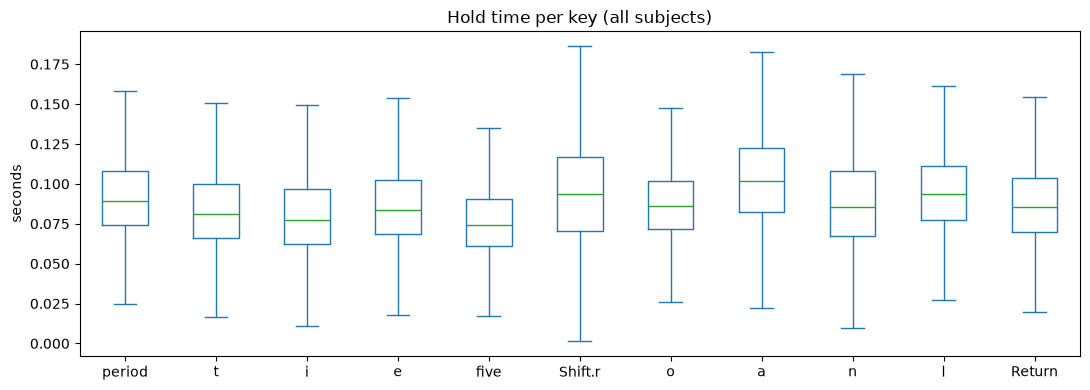

In [5]:
h_cols = [c for c in cols if c.startswith('H.')]
ax = df[h_cols].plot.box(figsize=(11, 4), showfliers=False, rot=0)
ax.set_xticklabels([c[2:] for c in h_cols])
ax.set(title='Hold time per key (all subjects)', ylabel='seconds')
plt.tight_layout(); plt.show()

### 2-2. 사람마다 타이핑 속도가 다른가?
한 번 입력에 걸린 총 시간(첫 키 누름 → Enter 누름 = DD 합계)을 사람별로 비교한다. 차이가 클수록 "리듬으로 사람 구분"이 가능하다는 근거가 된다.

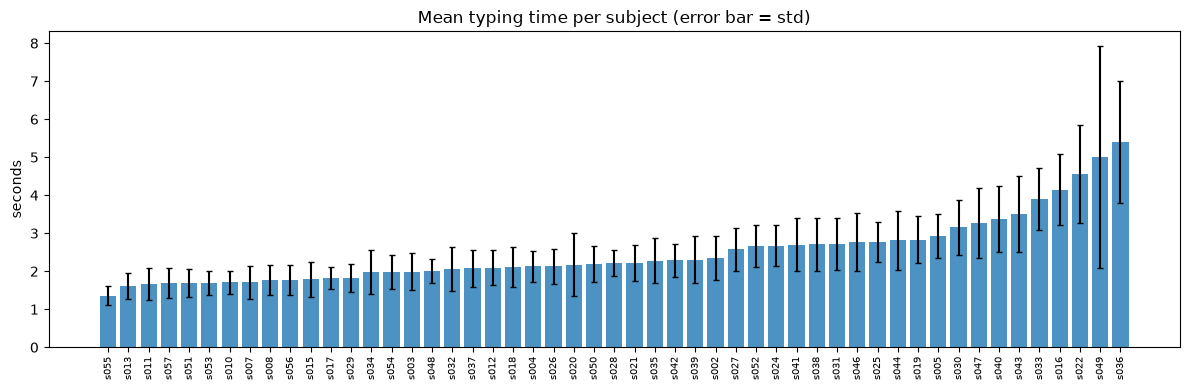

가장 빠른 사람 s055: 1.36초  /  가장 느린 사람 s036: 5.40초


In [6]:
dd_cols = [c for c in cols if c.startswith('DD.')]
df['total_time'] = df[dd_cols].sum(axis=1)
per = df.groupby('subject').total_time.agg(['mean', 'std']).sort_values('mean')

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(per)), per['mean'], yerr=per['std'], capsize=2, color='tab:blue', alpha=0.8)
ax.set_xticks(range(len(per)), per.index, rotation=90, fontsize=7)
ax.set(title='Mean typing time per subject (error bar = std)', ylabel='seconds')
plt.tight_layout(); plt.show()
print(f"가장 빠른 사람 {per.index[0]}: {per['mean'].iloc[0]:.2f}초  /  가장 느린 사람 {per.index[-1]}: {per['mean'].iloc[-1]:.2f}초")

### 2-3. 시간이 지나면 리듬이 바뀌는가? (학습 효과)
같은 비밀번호를 반복할수록 손에 익어 빨라질 수 있다. 이는 **평가 방법 설계**에 중요하다.

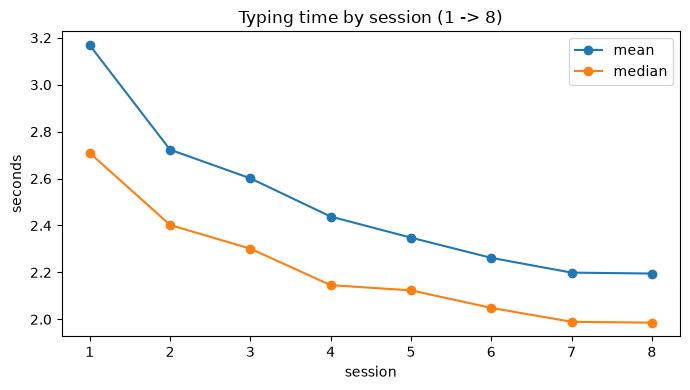

sessionIndex,1,2,3,4,5,6,7,8
mean,3.168,2.723,2.601,2.438,2.348,2.262,2.199,2.195
median,2.709,2.402,2.301,2.146,2.124,2.049,1.990,1.986


In [7]:
sess = df.groupby('sessionIndex').total_time.agg(['mean', 'median'])
ax = sess.plot(marker='o', figsize=(7, 4))
ax.set(title='Typing time by session (1 -> 8)', xlabel='session', ylabel='seconds')
plt.tight_layout(); plt.show()
display(sess.round(3).T)

**해석**: 세션이 지날수록 입력 시간이 줄어든다. 즉 같은 사람이라도 리듬이 조금씩 변한다.
그래서 평가할 때 데이터를 무작위로 섞지 않고 **앞 200회로 학습, 뒤 200회로 평가**한다.
무작위로 섞으면 미래의 리듬을 미리 보고 학습하는 셈이라 성능이 실제보다 좋게 나온다.

### 2-4. 사람별로 리듬이 구분되는가? (PCA 시각화)
31차원 특징을 2차원으로 줄여 5명의 입력을 점으로 찍어본다.

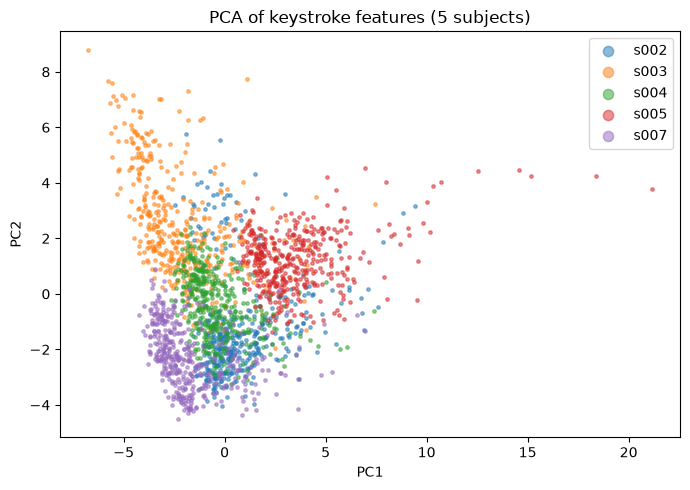

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sample_subj = sorted(df.subject.unique())[:5]
sub = df[df.subject.isin(sample_subj)]
Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(sub[cols]))

fig, ax = plt.subplots(figsize=(7, 5))
for s in sample_subj:
    m = (sub.subject == s).values
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.5, label=s)
ax.set(title='PCA of keystroke features (5 subjects)', xlabel='PC1', ylabel='PC2')
ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

**해석**: 사람마다 점들이 대체로 다른 영역에 모인다. 다만 일부 겹치는 사람도 있어, 완벽한 구분은 어렵고 오류율이 0이 되지는 않을 것으로 예상된다.

## 3. 평가 방법

**표준 평가 방식 (Killourhy & Maxion 2009와 동일)**
- 본인 학습: 처음 200회 입력 (본인 데이터만 사용, 타인 데이터는 학습에 쓰지 않음)
- 본인 테스트: 나머지 200회
- 사칭자 테스트: 다른 50명의 처음 5회씩 = 250회

**지표**
- **FAR (타인 수락률)**: 사칭자를 본인으로 잘못 통과시킨 비율 → 보안 문제
- **FRR (본인 거부율)**: 본인을 잘못 차단한 비율 → 불편 문제
- **EER (동일 오류율)**: 임계값을 조절해 FAR = FRR이 되는 지점의 오류율. **낮을수록 좋다.**

**모델**
- **디노이징 오토인코더 (딥러닝)**: 본인 리듬만으로 "복원"을 학습한다. 본인 입력은 잘 복원되고, 타인 입력은 복원 오차가 크다 → 오차 = 이상 점수
- **Scaled Manhattan (기준 모델)**: 원 논문에서 가장 성능이 좋았던 거리 기반 방법

## 4. 한 명 상세 분석 (s002)

s002  학습 (200, 31), 본인 테스트 (200, 31), 사칭자 테스트 (250, 31)


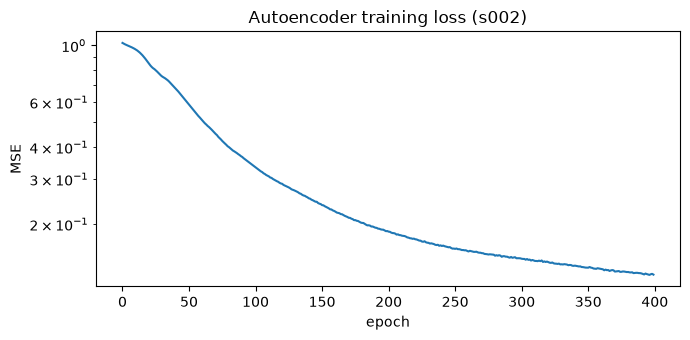

In [9]:
S = config.DEMO_SUBJECT
train, gen_test, imp_test = split_subject(df, cols, S)
print(f'{S}  학습 {train.shape}, 본인 테스트 {gen_test.shape}, 사칭자 테스트 {imp_test.shape}')

ae = Verifier().fit(train, epochs=400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ae.history)
ax.set(title=f'Autoencoder training loss ({S})', xlabel='epoch', ylabel='MSE', yscale='log')
plt.tight_layout(); plt.show()

오토인코더 EER = 0.265  (임계값 0.881)


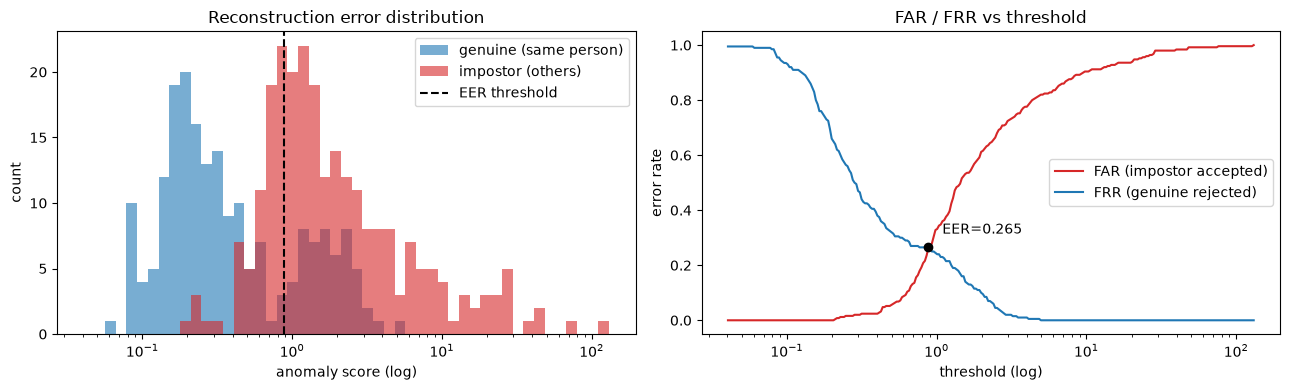

In [10]:
g, i = ae.score(gen_test), ae.score(imp_test)
e, thr = eer(g, i)
print(f'오토인코더 EER = {e:.3f}  (임계값 {thr:.3f})')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.logspace(np.log10(min(g.min(), i.min())), np.log10(max(g.max(), i.max())), 50)
axes[0].hist(g, bins=bins, alpha=0.6, label='genuine (same person)', color='tab:blue')
axes[0].hist(i, bins=bins, alpha=0.6, label='impostor (others)', color='tab:red')
axes[0].axvline(thr, c='k', ls='--', label='EER threshold')
axes[0].set(xscale='log', title='Reconstruction error distribution', xlabel='anomaly score (log)', ylabel='count')
axes[0].legend()

ts = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), 300)
ff = np.array([far_frr(g, i, t) for t in ts])
axes[1].plot(ts, ff[:, 0], label='FAR (impostor accepted)', c='tab:red')
axes[1].plot(ts, ff[:, 1], label='FRR (genuine rejected)', c='tab:blue')
axes[1].scatter([thr], [e], c='k', zorder=3); axes[1].annotate(f'EER={e:.3f}', (thr, e), xytext=(10, 10), textcoords='offset points')
axes[1].set(xscale='log', title='FAR / FRR vs threshold', xlabel='threshold (log)', ylabel='error rate')
axes[1].legend()
plt.tight_layout(); plt.show()

In [11]:
man = ScaledManhattan().fit(train)
e_man, _ = eer(man.score(gen_test), man.score(imp_test))
print(f'{S}: 오토인코더 EER = {e:.3f} / Scaled Manhattan EER = {e_man:.3f}')

s002: 오토인코더 EER = 0.265 / Scaled Manhattan EER = 0.240


**해석**: 본인(파랑)의 복원 오차는 낮은 쪽에, 사칭자(빨강)는 높은 쪽에 몰려 있다. 두 분포가 겹치는 부분이 오류가 된다.
임계값을 낮추면 FAR은 줄지만 FRR이 늘어나는 **보안-편의 트레이드오프**가 있다. EER은 두 오류가 같아지는 지점이다.

## 5. 51명 전체 평가

한 명만 보면 우연일 수 있으므로 51명 모두에 대해 같은 방식으로 평가하고 평균을 낸다. CPU에서 1~3분 정도 걸린다.

In [12]:
%%time
res = evaluate_all(df, cols, epochs=400, verbose=False)
summary = summarize(res)
display(res.describe().round(3))

,eer_autoencoder,eer_manhattan
count,51.000,51.000
mean,0.104,0.096
std,0.063,0.069
min,0.009,0.009
25%,0.062,0.048
50%,0.096,0.080
75%,0.133,0.116
max,0.269,0.324


CPU times: total: 3min 24s
Wall time: 53.9 s


,모델,평균 EER,표준편차
0,디노이징 오토인코더 (딥러닝),0.104284,0.063325
1,Scaled Manhattan (기준),0.096,0.069375
2,논문 최고 성능 (참고),0.096 ~ 0.102,-


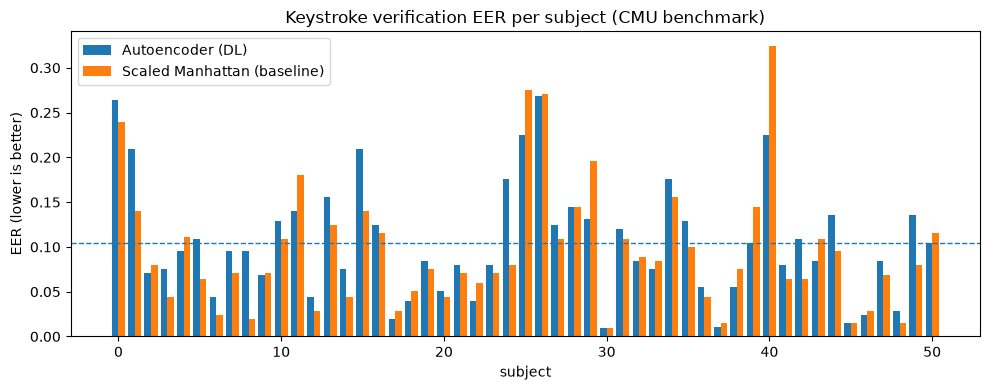

In [13]:
display(pd.DataFrame({
    '모델': ['디노이징 오토인코더 (딥러닝)', 'Scaled Manhattan (기준)', '논문 최고 성능 (참고)'],
    '평균 EER': [summary['autoencoder_eer_mean'], summary['manhattan_eer_mean'], '0.096 ~ 0.102'],
    '표준편차': [summary['autoencoder_eer_std'], summary['manhattan_eer_std'], '-'],
}).round(3))
fig = plot_eer(res, summary)
plt.show()

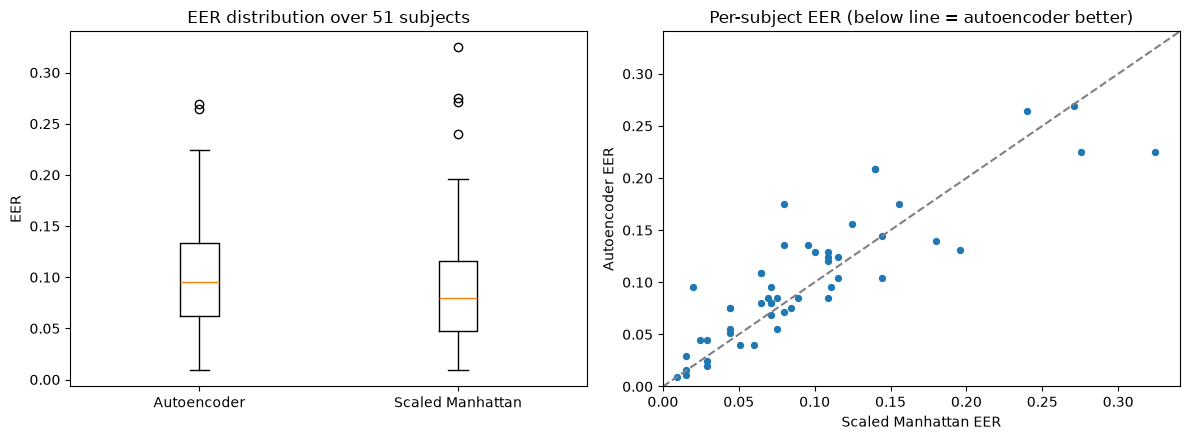

오토인코더가 더 좋은 사람: 19명 / 같음: 3명 / 기준 모델이 더 좋은 사람: 29명
Wilcoxon 부호순위 검정 p-value = 0.039


In [14]:
from scipy.stats import wilcoxon

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].boxplot([res.eer_autoencoder, res.eer_manhattan])
axes[0].set_xticks([1, 2], ['Autoencoder', 'Scaled Manhattan'])
axes[0].set(title='EER distribution over 51 subjects', ylabel='EER')

axes[1].scatter(res.eer_manhattan, res.eer_autoencoder, s=18)
lim = max(res.eer_manhattan.max(), res.eer_autoencoder.max()) * 1.05
axes[1].plot([0, lim], [0, lim], '--', c='gray')
axes[1].set(title='Per-subject EER (below line = autoencoder better)', xlabel='Scaled Manhattan EER', ylabel='Autoencoder EER',
            xlim=(0, lim), ylim=(0, lim))
plt.tight_layout(); plt.show()

better = (res.eer_autoencoder < res.eer_manhattan).sum()
same = (res.eer_autoencoder == res.eer_manhattan).sum()
stat, p = wilcoxon(res.eer_autoencoder, res.eer_manhattan)
print(f'오토인코더가 더 좋은 사람: {better}명 / 같음: {same}명 / 기준 모델이 더 좋은 사람: {51 - better - same}명')
print(f'Wilcoxon 부호순위 검정 p-value = {p:.3f}')

In [15]:
print('EER이 가장 높은(구분이 어려운) 5명')
display(res.sort_values('eer_autoencoder', ascending=False).head().round(3))
save_results(res, summary, fig)
print('저장:', config.REPORT_DIR / 'keystroke_eer.csv', config.REPORT_DIR / 'keystroke_summary.json')

EER이 가장 높은(구분이 어려운) 5명


,subject,eer_autoencoder,eer_manhattan
26,s032,0.269,0.271
0,s002,0.264,0.240
25,s031,0.224,0.276
40,s047,0.224,0.324
1,s003,0.209,0.140


저장: C:\Users\human-16\Desktop\test\login-guard-ai\reports\keystroke_eer.csv C:\Users\human-16\Desktop\test\login-guard-ai\reports\keystroke_summary.json


## 6. 시연용 모델 저장

앱에서 시연할 "데모 사용자"(s002) 모델을 만든다. 이번에는 임계값을 정하기 위해 데이터를 3등분한다.
- 1~200회: 학습 / 201~300회: 임계값 결정(검증) / 301~400회: 시연용 본인 샘플
- 시연용 사칭 샘플은 검증에 쓰지 않은 마지막 세션에서 뽑아, 정해진 임계값이 처음 보는 데이터에서도 통하는지 확인한다.

In [16]:
from src.keystroke.train_demo import main as train_demo
_, demo = train_demo()

데모 사용자 s002: 검증 EER=0.078, threshold=0.4544
시연 샘플 기준  본인 거부율(FRR)=0.560, 타인 통과율(FAR)=0.190
saved: C:\Users\human-16\Desktop\test\login-guard-ai\models\keystroke_demo.pt C:\Users\human-16\Desktop\test\login-guard-ai\models\keystroke_demo_samples.npz


## 7. 결론

**데이터 분석에서 알게 된 점**
- 51명 × 400회, 31개 시간 특징, 결측치 없음. 일부 극단값(한 키 간격 12초 이상 등)은 입력 중 멈춘 경우로 보이며, 모델은 특징을 표준화해서 사용한다.
- 평균 입력 시간이 가장 빠른 사람 1.36초, 가장 느린 사람 5.40초로 **개인차가 커서** 리듬으로 사람을 구분할 근거가 된다.
- 세션 1 → 8로 갈수록 평균 3.17초 → 2.20초로 빨라졌다(**학습 효과**). 그래서 시간 순서대로 학습/평가를 나눴다.

**모델 평가 결과 (51명 평균 EER, 낮을수록 좋음)**

| 모델 | 평균 EER |
|---|---|
| 디노이징 오토인코더 (딥러닝) | 0.104 ± 0.063 |
| Scaled Manhattan (기준 모델) | 0.096 ± 0.069 |
| 원 논문 최고 성능 | 0.096 ~ 0.102 |

- 두 모델 모두 원 논문 수준의 성능을 재현했다. 약 10%의 확률로 오류가 난다는 뜻이다.
- 사람별로 보면 오토인코더가 더 좋은 사람 19명, 기준 모델이 더 좋은 사람 29명(같음 3명). Wilcoxon 검정 p = 0.039로 **기준 모델이 통계적으로 약간 우세**했다.
- 본인 학습 데이터가 200개뿐이라 딥러닝의 장점이 드러나기 어려운 조건이다. **딥러닝이 항상 더 좋은 것은 아니라는 점**을 확인했다.

**시연용 모델에서 발견한 문제**
- 검증 데이터(201~300회)로 정한 임계값의 EER은 0.078이었지만, 시연 샘플(301~400회)에서는 **본인 거부율이 56%**로 크게 올랐다(타인 통과율 19%).
- 2-3에서 본 학습 효과 때문에 뒤쪽 세션의 리듬이 학습 때와 달라졌기 때문이다.
- 실제 서비스라면 로그인에 성공할 때마다 최근 입력으로 모델을 **갱신(재학습)**하거나, 단독 차단 대신 **추가 인증을 요구하는 보조 신호**로 쓰는 것이 적절하다.